In [1]:
# Parameters
BATCH_MODE = "true"
N_SWEEP = 50
SEEDS = 12
N_ORACLE = 8

# Complexity-02b — Le seuil du 3-SAT, mesuré contre la densité

**Navigation** : [Index](README.md) | [02 — Vérifier ou trouver](Complexity-02-P-NP-Reduction.ipynb) | [03 — Plus de temps, plus de problèmes →](Complexity-03-TimeHierarchy.ipynb)

La série parle de « densité-seuil `4,267n` ». Ce carnet trace la courbe qui donne un sens à ces mots :
le taux de satisfaisabilité et le coût de la recherche, **contre `m/n`**, à taille fixe — et le contrôle
discriminant qui montre que ce n'est pas le seuil qui coûte cher, c'est le problème.

## 0. Pourquoi ce carnet

Le palier [02 — Vérifier ou trouver : P, NP, certificat, réduction](Complexity-02-P-NP-Reduction.ipynb)
a posé SAT comme le problème de décision qui définit NP, et le mur exponentiel face à une machine plus rapide.

L'accrétion [03c — Naviguer le Zoo exécutable](Complexity-03c-ComplexityZoo-Navigation-Python.ipynb)
mesure ensuite la croissance du coût **en fonction de `n`**, à densité fixe : combien de nœuds DPLL
supplémentaires par variable. Sa ligne de README y ajoute la valeur `densité-seuil 4,267n` — en prose.

Ce carnet prend l'**autre axe**. `n` fixe, on fait varier le nombre de clauses. Trois choses en sortent :

1. la **satisfaisabilité** n'est pas une propriété monotone lisse : elle tombe dans une bande étroite ;
2. le **coût** de la recherche culmine dans cette même bande — et l'endroit du pic dépend de la
   statistique qu'on regarde ;
3. un **contrôle** : le 2-SAT a un seuil de satisfaisabilité lui aussi, et son coût montre un relief
   du même signe mais d'un tout autre ordre de grandeur (pic 111 contre 1059 nœuds). Le seuil ne
   suffit donc pas à fabriquer la difficulté ; c'est la classe de complexité qui la fabrique.

Ce carnet ne prétend pas établir la valeur du seuil. Il mesure une **bande** et déclare sa résolution.


## 1. Trois niveaux, et un quatrième pour ce qu'on ne fait pas

La série distingue **Mesuré** (produit par une cellule de ce carnet), **Cité** (vient d'une source
externe, non reproduit ici) et **Absent** (ni l'un ni l'autre). Ce carnet ajoute un quatrième statut,
celui qu'on oublie le plus souvent : **non résolu par la mesure** — l'expérience a eu lieu, mais son
échantillon ne permet pas de trancher la question posée.

| Affirmation | Statut dans ce carnet |
|---|---|
| Le DPLL de ce carnet est correct sur les petites instances | **Mesuré** — confronté à l'énumération exhaustive |
| `P(satisfaisable)` chute d'une bande à l'autre quand `m/n` croît | **Mesuré** |
| Le coût de la recherche culmine dans la bande de transition | **Mesuré** (avec la dépendance à la statistique) |
| Le 2-SAT a un seuil de satisfaisabilité, et un pic de coût d'un ordre de grandeur moindre que le 3-SAT | **Mesuré** |
| La bande de transition se resserre quand `n` croît | **Mesuré**, grossièrement (trois tailles) |
| La valeur `4,267` du seuil 3-SAT | **Cité** — et **non résolu** par cet échantillon (voir §6) |
| Le seuil exact pour `n → ∞`, `k = 3` | **Absent** — aucune valeur n'en est démontrée : elle est inconnue (voir ci-dessous) |

**Ce qui est démontré, et ce qui ne l'est pas.** La dernière ligne mérite d'être lue précisément, parce
que c'est le point où deux énoncés se confondent le plus facilement. Pour `k = 2`, le seuil **est** un
théorème et vaut `1`. Pour `k = 3`, aucune valeur n'est démontrée : ce qui est établi est l'**existence
d'un seuil net** — la fenêtre de transition devient négligeable devant la position du seuil (Friedgut) —
et des **bornes** encadrant ce seuil. La valeur `4,267` n'est donc pas un théorème : c'est une prédiction
issue de méthodes non rigoureuses. C'est justement l'intérêt pédagogique de cette section — le cas
canonique où l'expérience et la physique statistique devancent la preuve.

Les références classiques de ce domaine — Cheeseman, Kanefsky & Taylor (*Where the really hard problems
are*, IJCAI-91) et Mitchell, Selman & Levesque (*Hard and easy distributions of SAT problems*, AAAI-92) —
sont nommées ici au niveau **Cité**, comme Friedgut pour l'existence du seuil net. Elles n'ont pas été
relues pour ce carnet, et aucun chiffre n'en est recopié : tout ce qui est affirmé quantitativement
ci-dessous est produit par les cellules.


In [2]:
import itertools
import random
import statistics
import time

import matplotlib.pyplot as plt

# Toutes les instances sont generees sous graine fixee : les chiffres de ce
# carnet sont reproductibles a l'identique.
GRAINE_BASE = 20261023

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("constantes posees :", N_SWEEP, "variables,", SEEDS, "instances par point")

constantes posees : 50 variables, 12 instances par point


## 2. Les instances : uniformes, et générées sous graine

Une instance `k`-SAT est tirée uniformément : `m` clauses, chacune sur `k` variables **distinctes**,
chaque littéral de signe aléatoire. C'est la distribution standard — celle dont on parle quand on dit
« 3-SAT aléatoire ». Le seul paramètre qui varie dans la suite est `m/n`.


In [3]:
def generer_instance(n, m, k, graine):
    """m clauses de k litteraux sur n variables, variables distinctes par clause."""
    rnd = random.Random(graine)
    clauses = []
    while len(clauses) < m:
        variables = rnd.sample(range(1, n + 1), k)
        clauses.append(tuple(v if rnd.random() < 0.5 else -v for v in variables))
    return clauses


exemple = generer_instance(6, 8, 3, GRAINE_BASE)
print(len(exemple), "clauses,", len({abs(l) for c in exemple for l in c}), "variables touchees")
print(exemple[:4])

8 clauses, 6 variables touchees
[(-3, 6, 2), (-4, 1, 6), (5, 3, 6), (5, -4, 2)]


### 2.1 Le solveur : DPLL avec propagation unitaire

Deux opérations, et c'est tout :

- **simplifier** — retirer les clauses déjà satisfaites par l'affectation courante, et réduire les autres ;
  une clause vidée signifie que la branche est morte ;
- **propager** — une clause réduite à un seul littéral force sa variable ; on répète jusqu'au point fixe.

On compte **un nœud** par appel de la récursion, c'est-à-dire par état partiel examiné. Ce compteur est
la seule mesure de coût du carnet : il ne dépend ni de la machine, ni du langage, ni d'un chronomètre.

Le parcours est itératif (une pile explicite) pour ne pas heurter la limite de récursion de Python sur
les instances les plus dures.


In [4]:
def propager(clauses, affectation):
    """Propagation unitaire jusqu'au point fixe. Rend (ok, clauses reduites)."""
    clauses = list(clauses)
    while True:
        unitaire = next((c[0] for c in clauses if len(c) == 1), None)
        if unitaire is None:
            return True, clauses
        variable, positif = abs(unitaire), unitaire > 0
        if variable in affectation and affectation[variable] != positif:
            return False, None
        affectation[variable] = positif
        restantes = []
        for clause in clauses:
            if unitaire in clause:
                continue
            reduite = tuple(l for l in clause if l != -unitaire)
            if not reduite:
                return False, None
            restantes.append(reduite)
        clauses = restantes


def simplifier(clauses, affectation):
    """Applique une affectation puis propage. Rend (pas_de_conflit, clauses)."""
    gardees = []
    for clause in clauses:
        restants, satisfaite = [], False
        for litteral in clause:
            variable = abs(litteral)
            if variable in affectation:
                if affectation[variable] == (litteral > 0):
                    satisfaite = True
                    break
            else:
                restants.append(litteral)
        if satisfaite:
            continue
        if not restants:
            return False, None
        gardees.append(tuple(restants))
    return propager(gardees, affectation)


def dpll(clauses, affectation=None):
    """DPLL iteratif. Rend (satisfaisable, nombre de noeuds examines)."""
    affectation = {} if affectation is None else dict(affectation)
    noeuds = 0
    pile = [(clauses, affectation)]
    while pile:
        clauses, affectation = pile.pop()
        noeuds += 1
        ok, reduites = simplifier(clauses, dict(affectation))
        if not ok:
            continue
        if not reduites:
            return True, noeuds
        variable = min(abs(l) for c in reduites for l in c)
        for valeur in (True, False):
            suite = dict(affectation)
            suite[variable] = valeur
            pile.append((reduites, suite))
    return False, noeuds


print("solveur en place")

solveur en place


### 2.2 Avant de mesurer quoi que ce soit : vérifier le solveur

Les courbes qui suivent n'ont de valeur que si le solveur qui les produit est correct. On le confronte
donc à un **oracle indépendant** : l'énumération exhaustive des `2^n` affectations, sur 30 instances de
`n = 8`. L'oracle ne partage aucun code avec DPLL — c'est la seule chose qui compte : deux programmes
d'accord, ce n'est pas une preuve, mais une divergence serait une preuve de bug.


In [5]:
def oracle_brut(instance, n):
    """Enumeration exhaustive des 2^n affectations. Independant de DPLL."""
    for bits in itertools.product((False, True), repeat=n):
        valeur = {i + 1: bits[i] for i in range(n)}
        if all(any(valeur[abs(l)] == (l > 0) for l in c) for c in instance):
            return True
    return False


desaccords = []
for essai in range(30):
    instance = generer_instance(N_ORACLE, round(4.26 * N_ORACLE), 3, GRAINE_BASE + 1000 + essai)
    par_dpll, _ = dpll(instance)
    par_oracle = oracle_brut(instance, N_ORACLE)
    if par_dpll != par_oracle:
        desaccords.append(essai)

print(f"instances confrontees : 30   desaccords : {len(desaccords)}")

instances confrontees : 30   desaccords : 0


### Lecture du résultat — l'oracle : zéro désaccord, et sa portée exacte

Zéro désaccord sur 30 instances. Le DPLL et l'énumération exhaustive tombent d'accord partout. C'est le
**préalable** de toute la suite : on mesure désormais avec un instrument dont on a vu qu'il ne se trompe
pas sur ce qu'on sait vérifier.

Le mélange de l'échantillon mérite d'être chiffré, parce qu'il limite la portée du contrôle : **27
instances satisfaisables sur 30**, trois insatisfaisables. Les deux réponses sont donc représentées — mais
l'insatisfaisable ne l'est que trois fois. Un bug qui ne se déclencherait que sur les instances
insatisfaisables profondes passerait inaperçu ici. Le contrôle est réel, il n'est pas exhaustif.

Sa portée exacte, enfin : il valide le solveur à `n = 8`. Il ne prouve pas que le parcours reste correct
à `n = 50` — il n'y a simplement plus d'oracle disponible à cette taille. C'est une garantie par
continuité du code, pas une preuve.

## 3. La courbe que la série ne traçait pas

`n` fixé à 50. On balaie `m/n` de 2,0 à 6,0. Pour chaque densité, 12 instances tirées sous graines
distinctes, résolues par DPLL. On relève trois nombres : la **fraction satisfaisable**, la **médiane**
des nœuds, et le **maximum** des nœuds.

La médiane et le maximum mesurent deux choses différentes : la médiane décrit l'instance typique, le
maximum décrit la pire instance tirée. Les deux ont leur mot à dire sur « où est la difficulté ».


In [6]:
def balayer(n, k, densites, graines):
    """Pour chaque densite : fraction sat, mediane et maximum des noeuds."""
    resultats = []
    for densite in densites:
        m = int(round(densite * n))
        sat, noeuds = 0, []
        for graine in graines:
            instance = generer_instance(n, m, k, graine)
            ok, compte = dpll(instance)
            sat += ok
            noeuds.append(compte)
        resultats.append({"densite": densite, "m": m,
                          "p_sat": sat / len(graines),
                          "mediane": statistics.median(noeuds),
                          "maximum": max(noeuds)})
    return resultats


def afficher(resultats, titre):
    print(titre)
    print(f"  {'m/n':>5} {'m':>5} {'P(sat)':>7} {'noeuds med':>11} {'noeuds max':>11}")
    for r in resultats:
        print(f"  {r['densite']:5.2f} {r['m']:5d} {r['p_sat']:7.2f} "
              f"{r['mediane']:11.0f} {r['maximum']:11d}")


densites_3sat = (2.0, 3.0, 3.5, 4.0, 4.26, 4.5, 5.0, 6.0)
debut = time.perf_counter()
res_3sat = balayer(N_SWEEP, 3, densites_3sat, range(SEEDS))
duree_3sat = time.perf_counter() - debut
afficher(res_3sat, f"3-SAT, n = {N_SWEEP}, {SEEDS} instances par point")
print(f"duree du balayage : {duree_3sat:.1f} s")

3-SAT, n = 50, 12 instances par point
    m/n     m  P(sat)  noeuds med  noeuds max
   2.00   100    1.00          24          27
   3.00   150    1.00          18          31
   3.50   175    1.00          17         122
   4.00   200    0.83          53         727
   4.26   213    0.67         148        1059
   4.50   225    0.33         454         709
   5.00   250    0.08         277         581
   6.00   300    0.00         201         273
duree du balayage : 17.5 s


### Lecture du résultat — trois régimes, et le ventre au milieu

Trois régimes se lisent d'un trait, et ils ne se ressemblent pas :

- **en dessous de 3,5** — toutes les instances sont satisfaisables, et le coût est **plat** : une vingtaine
  de nœuds. Le problème est facile, et il l'est pour une raison simple : il y a peu de clauses, donc peu
  de contraintes, donc DPLL trouve une affectation avec très peu de retour arrière.
- **entre 4,0 et 5,0** — la fraction satisfaisable tombe (0,83 → 0,33), et le coût décolle de plus d'un
  ordre de grandeur. C'est la bande où les deux régimes se mélangent.
- **à 6,0** — plus rien n'est satisfaisable, et le coût **redescend** sous son niveau de la bande. Une
  instance insatisfaisable est souvent réfutée vite : la contradiction est locale et la propagation seule
  la trouve. « Difficile » n'est donc pas synonyme de « sans solution » — c'est le mélange des deux qui coûte.

Ce dernier point est le plus utile pédagogiquement : la difficulté n'est pas une fonction croissante de la
densité. Elle a un **ventre**, et il faut le voir pour le croire.

### 3.1 Les deux courbes, côte à côte

Deux panneaux, même axe des abscisses : à gauche la fraction satisfaisable, à droite le coût. La bande de
transition est la même des deux côtés — c'est précisément ce que ce carnet veut établir.


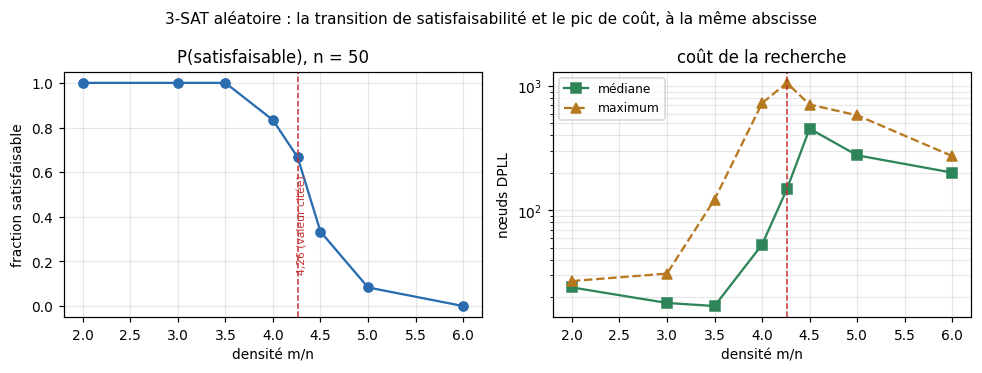

m/n = 4.00 : médiane 53, maximum 727
m/n = 4.26 : médiane 148, maximum 1059
m/n = 4.50 : médiane 454, maximum 709


In [7]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(9, 3.4))

densites = [r["densite"] for r in res_3sat]
gauche.plot(densites, [r["p_sat"] for r in res_3sat], "o-", color="#2b6cb0")
gauche.set_xlabel("densité m/n")
gauche.set_ylabel("fraction satisfaisable")
gauche.set_title(f"P(satisfaisable), n = {N_SWEEP}")
gauche.grid(alpha=0.3)
gauche.axvline(4.26, color="#c53030", linestyle="--", linewidth=1)
gauche.annotate("4,26 (valeur citée)", (4.26, 0.15), rotation=90, fontsize=7, color="#c53030")

droite.plot(densites, [r["mediane"] for r in res_3sat], "s-", label="médiane", color="#2f855a")
droite.plot(densites, [r["maximum"] for r in res_3sat], "^--", label="maximum", color="#b7791f")
droite.set_xlabel("densité m/n")
droite.set_ylabel("nœuds DPLL")
droite.set_yscale("log")
droite.set_title("coût de la recherche")
droite.grid(alpha=0.3, which="both")
droite.legend(fontsize=8)
droite.axvline(4.26, color="#c53030", linestyle="--", linewidth=1)

fig.suptitle("3-SAT aléatoire : la transition de satisfaisabilité et le pic de coût, à la même abscisse", fontsize=10)
fig.tight_layout()
plt.show()

for r in res_3sat:
    if r["densite"] in (4.0, 4.26, 4.5):
        print(f"m/n = {r['densite']:.2f} : médiane {r['mediane']:.0f}, maximum {r['maximum']}")

### Lecture de la figure

Le panneau de gauche montre une marche descendante, pas une pente douce : entre 3,5 et 5,0 la fraction
satisfaisable perd l'essentiel de sa valeur. Le panneau droit montre un ventre, sur le **même intervalle**.

Un détail mérite d'être vu plutôt que lissé : les deux statistiques ne culminent pas au même endroit.
La **médiane** culmine un cran à droite du maximum — l'instance typique reste coûteuse un peu plus loin
dans la bande ; le **maximum** culmine plus à gauche, à `4,26`. Autrement dit : « le pic est à 4,26 » est
une phrase qui dépend de ce qu'on appelle « difficile ».

Ce qui distingue l'instance la plus chère, l'instrument ne le dit pas : `balayer()` ne conserve ni la
graine ni le verdict satisfaisable/insatisfaisable de l'instance qui fixe le maximum — seulement le
compte. À `m/n = 4,26`, la fraction satisfaisable vaut 0,67 : les instances satisfaisables y sont
majoritaires. Attribuer le pic à une famille d'instances précise exigerait de rejouer le balayage en
retenant `(graine, nœuds, satisfaisable)` ; ce carnet ne le fait pas, et s'abstient de le conjecturer.

L'échelle du panneau de droite est logarithmique. Sans elle, la marche d'un facteur vingt entre le régime
facile et la bande serait illisible — et c'est bien d'un ordre de grandeur qu'on parle.


## 4. Le contrôle qui fait tout le travail : le 2-SAT

Une courbe de difficulté qui culmine près d'un seuil ne prouve rien tant qu'on n'a pas montré qu'un
**seuil ne suffit pas** à produire cette difficulté. Le 2-SAT fournit le témoin : il a lui aussi une
transition de satisfaisabilité, et son seuil est connu pour être linéaire (autour de `m/n = 1`).

Même générateur, même solveur, même compteur. Seul `k` change : 2 au lieu de 3.


In [8]:
densites_2sat = (0.5, 0.8, 1.0, 1.2, 2.0, 4.26)
debut = time.perf_counter()
res_2sat = balayer(N_SWEEP, 2, densites_2sat, range(SEEDS))
duree_2sat = time.perf_counter() - debut
afficher(res_2sat, f"2-SAT, n = {N_SWEEP}, {SEEDS} instances par point")
print(f"duree du balayage : {duree_2sat:.1f} s")

2-SAT, n = 50, 12 instances par point
    m/n     m  P(sat)  noeuds med  noeuds max
   0.50    25    1.00          12          18
   0.80    40    1.00          13          16
   1.00    50    1.00          12          15
   1.20    60    0.83          11         111
   2.00   100    0.00           3           7
   4.26   213    0.00           3           5
duree du balayage : 0.2 s


### Lecture du résultat — le 2-SAT a un seuil, et un relief d'un autre ordre de grandeur

Le 2-SAT **a** une transition : les douze instances de `m/n = 1,0` sont satisfaisables, celles de `2,0`
ne le sont plus, et le passage se fait entre les deux (0,83 à `1,20`). Le seuil existe donc bien.

Et pourtant le coût ne bouge pratiquement pas. Au pire point du passage, le maximum atteint **111** nœuds
— soit **près de dix fois moins** que les 1059 nœuds du 3-SAT. Une fois la densité franchie, le coût
**s'effondre** : la médiane tombe à trois nœuds à `m/n = 2,0` comme à `4,26`.

Les deux balayages partagent un point, `m/n = 4,26` soit `m = 213` pour `n = 50` : là, le 3-SAT culmine à
**1059** nœuds et le 2-SAT à **5**, un facteur **212**. C'est la comparaison à retenir, parce qu'elle
porte sur la même taille, le même nombre de clauses et le même solveur. Le « près de dix fois » vient de
l'appariement inverse — le pic du 2-SAT (`1,20`) contre un point du 3-SAT hors de sa bande critique : il
mélange deux densités, là où le facteur 212 les fixe.

Ce que l'instrument mesure ici, et qu'il faut nommer précisément, c'est un **mécanisme** : la propagation
unitaire. Le solveur du carnet propage les clauses unitaires jusqu'au point fixe (`propager`, §2.1), et
ne branche qu'ensuite à la **même** procédure pour `k = 2` et pour `k = 3`, sans aucun pré-traitement
propre au 2-SAT. Ce qui diffère entre les deux lignes du tableau, ce n'est donc ni le générateur, ni le
solveur, ni la taille : c'est la forme que prend la contrainte quand `k` change — et, avec elle, la plage
de densité où le seuil tombe, comme le note la lecture de la comparaison plus bas. Sur une 2-CNF dense,
la propagation éteint l'instance en quelques nœuds ; sur une 3-CNF dense, elle laisse un arbre à
parcourir. L'écart des deux maxima — 111 contre 1059 — est la **trace de ce mécanisme dans le compteur**.

La classe de complexité, elle, reste une **lecture théorique** de cet écart, et c'est là qu'il faut la
laisser. Que le 2-SAT se décide en temps linéaire et le 3-SAT soit NP-complet *rend compte* de ce qu'on
observe ; ce n'est pas ce que le carnet a mesuré. Un compteur de nœuds sur douze instances par point et
`n = 50` ne mesure pas une classe de complexité — il mesure combien de nœuds **ce** solveur a ouverts sur
**ces** instances-là.

La formulation exacte, si l'on veut la garder en une ligne : **« à générateur, solveur et taille
identiques, `k = 2` produit un seuil sans ventre de coût là où `k = 3` produit les deux »** — observation
compatible avec la différence de classe, et non démonstration de celle-ci.


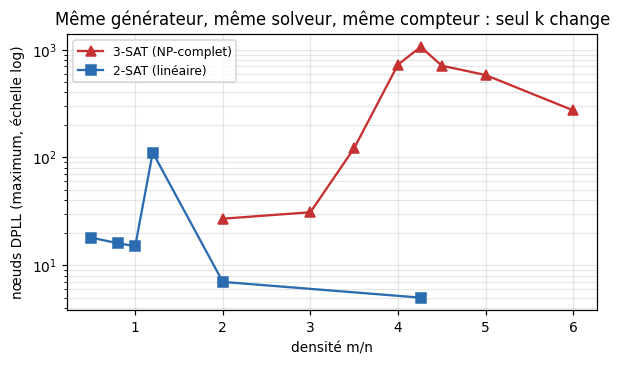

pic 3-SAT : 1059 noeuds   pic 2-SAT : 111 noeuds   rapport : 10x


In [9]:
fig, axe = plt.subplots(figsize=(5.6, 3.4))
axe.plot([r["densite"] for r in res_3sat], [r["maximum"] for r in res_3sat],
         "^-", color="#c53030", label="3-SAT (NP-complet)")
axe.plot([r["densite"] for r in res_2sat], [r["maximum"] for r in res_2sat],
         "s-", color="#2b6cb0", label="2-SAT (linéaire)")
axe.set_xlabel("densité m/n")
axe.set_ylabel("nœuds DPLL (maximum, échelle log)")
axe.set_yscale("log")
axe.set_title("Même générateur, même solveur, même compteur : seul k change")
axe.grid(alpha=0.3, which="both")
axe.legend(fontsize=8)
fig.tight_layout()
plt.show()

pic_3sat = max(r["maximum"] for r in res_3sat)
pic_2sat = max(r["maximum"] for r in res_2sat)
print(f"pic 3-SAT : {pic_3sat} noeuds   pic 2-SAT : {pic_2sat} noeuds   "
      f"rapport : {pic_3sat / pic_2sat:.0f}x")

### Lecture de la comparaison

Les deux courbes ne se contentent pas d'être à des hauteurs différentes : elles n'ont pas la même
**forme**. Celle du 3-SAT a un large ventre — un pic à environ 35 fois son plateau — et redescend sans
rejoindre son niveau de départ ; celle du 2-SAT garde un relief étroit (7,4 fois son plateau) puis
s'effondre *sous* son propre plateau de départ. Un facteur constant entre deux courbes parallèles aurait
seulement dit « le 3-SAT est plus cher » — un résultat sans intérêt. C'est la différence de **forme** et
d'**amplitude** qui porte l'information, et c'est pour cela que le contrôle est sur le même axe, avec les
mêmes unités.

Une limite de la comparaison, à écrire plutôt qu'à taire : les deux balayages ne couvrent pas le même
intervalle de densité, parce que leurs seuils ne sont pas au même endroit. La comparaison porte donc sur
les **pics**, pas sur les profils point par point. Comparer les profils exigerait de recentrer chaque
courbe sur sa propre densité critique — c'est l'exercice 1.


## 5. La bande se resserre-t-elle quand `n` croît ?

Une transition de phase, au sens physique, s'affûte : la bande de mélange se resserre à mesure que le
système grandit. C'est ce qui distingue une transition d'une simple pente.

Le test est direct : trois tailles, mêmes densités. Ce que la mesure peut montrer ici est **borné** par
la taille de l'échantillon, et le carnet le dira dans la lecture.


In [10]:
tailles = (20, 30, 40)
densites_affutage = (3.5, 4.0, 4.26, 4.5, 5.0)
res_affutage = {n: balayer(n, 3, densites_affutage, range(SEEDS)) for n in tailles}

entete = "  n  " + "".join(f"  m/n={d:<5.2f}" for d in densites_affutage)
print(entete)
for n in tailles:
    ligne = f" {n:3d} " + "".join(f"  P={r['p_sat']:<8.2f}" for r in res_affutage[n])
    print(ligne)

print()
for n in tailles:
    ligne = f" {n:3d} " + "".join(f"  {r['mediane']:>9.0f}" for r in res_affutage[n])
    print("med " + ligne + "   (noeuds, mediane)")

  n    m/n=3.50   m/n=4.00   m/n=4.26   m/n=4.50   m/n=5.00 
  20   P=1.00      P=0.92      P=0.92      P=0.83      P=0.42    
  30   P=1.00      P=0.83      P=0.67      P=0.50      P=0.17    
  40   P=1.00      P=0.67      P=0.50      P=0.50      P=0.00    

med   20          16         18         20         18         30   (noeuds, mediane)
med   30          24         52         78        105         87   (noeuds, mediane)
med   40          54        210        156        214        220   (noeuds, mediane)


### Lecture du résultat — le point de bascule glisse, la bande se resserre

À `m/n = 5,0`, la fraction satisfaisable passe de **0,42** à `n = 20` à **0,17** à `n = 30`, puis à
**0,00** à `n = 40` : le point de bascule se déplace vers la gauche et la bande se resserre. Même
mouvement à `4,26` (0,92 → 0,67 → 0,50). C'est la signature attendue d'une transition — et elle est
visible malgré un échantillon de douze instances.

Il faut cependant dire ce que ce mouvement vaut. Avec douze instances, une proportion voisine de 0,5
porte une erreur type d'environ **0,14**, donc un écart entre deux tailles voisines n'est pas significatif
(0,92 contre 0,67 fait 1,2σ environ). Seul l'écart entre les deux tailles extrêmes — 0,92 contre 0,50 à
`m/n = 4,26`, soit 2,2σ — approche le seuil de discrimination. La tendance est donc là ; elle n'est pas
établie taille par taille.

Une remarque qui découle de la mesure et qui vaut d'être notée : à `4,26`, `P(sat)` **décroît** avec `n`.
Si la tendance se maintenait, la valeur asymptotique du seuil serait *au-dessous* de 4,26, et non
exactement dessus. Un échantillon de cette taille ne permet pas de le conclure — mais il ne permet pas
non plus de présenter `4,267n` comme confirmé par la courbe, et c'est précisément la nuance que la
section suivante consigne.

## 6. Ce que ce carnet ne mesure pas

Un résultat honnête dit aussi sa portée. Trois limites, dont une qui concerne directement la valeur
citée par la série.

**La résolution de l'échantillon.** Avec douze instances par point et des tailles de 20 à 50, la bande
de transition mesurée fait environ une unité de `m/n` de large. La valeur `4,267` tombe **dans** cette
bande, mais aucun point du balayage ne permet de la distinguer de `4,0` ou de `4,5`. Classer `4,267`
comme *Mesuré* serait un abus de langage : ce carnet le classe **Cité**, et rapporte que sa propre mesure
est **compatible** avec, sans plus. Trancher la troisième décimale demanderait des tailles de plusieurs
centaines de variables et des milliers d'instances — hors du budget d'un carnet pédagogique.

**La dépendance à l'heuristique de branchement.** L'implémentation choisit toujours la variable de plus
petit indice. Une heuristique de type *most constrained variable* déplacerait le pic et écraserait les
comptes absolus. Les **formes** de courbes sont robustes (c'est la thèse du domaine) ; les **valeurs**
de nœuds affichées ici sont celles de ce solveur-là, pas une constante du problème.

**Le régime asymptotique.** Rien ici ne dit ce qui se passe quand `n → ∞`, et deux énoncés qu'on
confond souvent doivent y être séparés. L'**existence d'un seuil net** est un théorème : la fenêtre de
transition devient négligeable devant la position du seuil (Friedgut). La **valeur** de ce seuil pour
`k = 3` n'en est pas un : `4,267` est une prédiction non rigoureuse, encadrée par des bornes démontrées.
Le carnet ne fait que montrer qu'un phénomène de seuil est visible sur des tailles modestes, ce qui est
déjà remarquable.

Ce que le carnet **établit**, en revanche, est plus solide que la localisation d'un point : la difficulté
du 3-SAT aléatoire n'est pas monotone en la densité, elle est maximale dans la bande de transition — et
le 2-SAT, sur ce balayage, montre un relief du même signe mais d'un autre ordre de grandeur (pic 111
contre 1059, effondrement sous le plateau). Trois faits, mesurés, avec un contrôle.


## 7. Exercices

Trois exercices, exécutables sans erreur volontaire : les cellules s'exécutent telles quelles et
affichent leur énoncé tant qu'elles ne sont pas complétées.


### Exercice 1 — le seuil du 2-SAT, recentré sur ses propres densités

Le §4 a comparé les pics, faute d'intervalle commun. Recentrez la comparaison : balayez le 2-SAT sur
`0,7 / 0,9 / 1,0 / 1,1 / 1,3`, puis tracez son coût en fonction de `m/n - 1` (l'écart à son propre
seuil) et celui du 3-SAT en fonction de `m/n - 4,26`. Question à trancher par la figure : une fois
recentrées, les deux courbes ont-elles la même forme ?

*Indice* : `balayer(50, 2, (0.7, 0.9, 1.0, 1.1, 1.3), range(12))` vous donne les points ; le tracé
n'est qu'un décalage d'abscisse.


In [11]:
# Exercice 1 : recentrer la comparaison sur l'ecart au seuil de chaque famille
# TODO etudiant : reprendre le balayage 2-SAT ci-dessus, decaler les abscisses,
#                 tracer les deux courbes sur le meme axe (ecart au seuil)
print("Exercice 1 a completer : comparer les deux courbes recentrees sur leur seuil")

Exercice 1 a completer : comparer les deux courbes recentrees sur leur seuil


### Exercice 2 — une troisième statistique

Le §3 a montré que la médiane et le maximum ne culminent pas au même endroit. Ajoutez une troisième
statistique — le **90e centile** des nœuds — et regardez où elle culmine. Le pic se rapproche-t-il de la
médiane ou du maximum ? Que dit ce déplacement sur ce que « la difficulté » désigne ?

*Indice* : `statistics.quantiles(noeuds, n=10)[8]` donne le 90e centile. Modifiez `balayer` pour
collecter la statistique, ou recalculez les nœuds depuis `densites_3sat`.


In [12]:
# Exercice 2 : ajouter le 90e centile des noeuds et localiser son pic
# TODO etudiant : collecter les noeuds par densite, calculer le 90e centile,
#                 afficher le tableau a trois statistiques
print("Exercice 2 a completer : localiser le pic du 90e centile")

Exercice 2 a completer : localiser le pic du 90e centile


### Exercice 3 — le coût d'un certificat

Le palier [02](Complexity-02-P-NP-Reduction.ipynb) a posé qu'un certificat NP se **vérifie** en temps
polynomial. Mesurez-le ici, sur les instances satisfaisables de la bande : écrivez un vérificateur qui
prend une affectation et rend le nombre de littéraux lus, puis comparez ce nombre au nombre de nœuds
qu'a coûté la **recherche** de cette même affectation.

*Indice* : `dpll` ne rend pas l'affectation ; il faut la reconstruire en relançant la recherche avec la
même heuristique, ou modifier `dpll` pour la rendre. C'est justement là que le coût apparaît : chercher
coûte des nœuds, vérifier coûte des littéraux.


In [13]:
# Exercice 3 : comparer le cout de VERIFIER au cout de TROUVER
# TODO etudiant : ecrire verifier(instance, affectation) qui compte les litteraux lus,
#                 puis afficher le rapport (noeuds DPLL) / (litteraux verifies)
print("Exercice 3 a completer : cout d'un certificat contre cout de la recherche")

Exercice 3 a completer : cout d'un certificat contre cout de la recherche


## Résumé

| Ce que le carnet a produit | Où |
|---|---|
| Un DPLL vérifié contre l'énumération exhaustive (0 désaccord sur 30 instances) | §2.2 |
| La courbe `P(satisfaisable)` contre `m/n`, à `n` fixe | §3 |
| Le coût en nœuds contre `m/n`, médiane **et** maximum, avec la dépendance à la statistique | §3.1 |
| Le contraste 2-SAT / 3-SAT : chacun une transition de satisfaisabilité, relief d'un autre ordre de grandeur (pic 111 contre 1059, effondrement sous le plateau) | §4 |
| L'affûtage de la bande avec `n`, et la résolution de l'échantillon | §5 |
| La valeur `4,267` classée **Cité**, la mesure déclarée compatible mais non concluante | §6 |

Ce qui change pour la série : la ligne de README de
[03c](Complexity-03c-ComplexityZoo-Navigation-Python.ipynb) cite `4,267n` comme densité-seuil. Après ce
carnet, la formulation exacte est : *la bande de transition mesurée est compatible avec `4,267n` ; cette
valeur est citée, non reproduite ici, et elle n'est pas un théorème — c'est une prédiction encadrée par
des bornes démontrées.* La nuance coûte une phrase et évite deux confusions symétriques : présenter une
valeur citée comme une valeur mesurée, ou comme une valeur démontrée.

Ce qui reste ouvert, et qui n'est pas un oubli : la localisation fine du seuil (taille et volume hors
budget), la robustesse des profils à l'heuristique de branchement, et le régime asymptotique — dont seul
le fait qu'il existe un seuil net est démontré ; sa valeur pour `k = 3` reste une prédiction.

**Navigation** : [Index](README.md) | [02 — Vérifier ou trouver](Complexity-02-P-NP-Reduction.ipynb) | [03c — Naviguer le Zoo](Complexity-03c-ComplexityZoo-Navigation-Python.ipynb) | [03 — Plus de temps, plus de problèmes →](Complexity-03-TimeHierarchy.ipynb)
